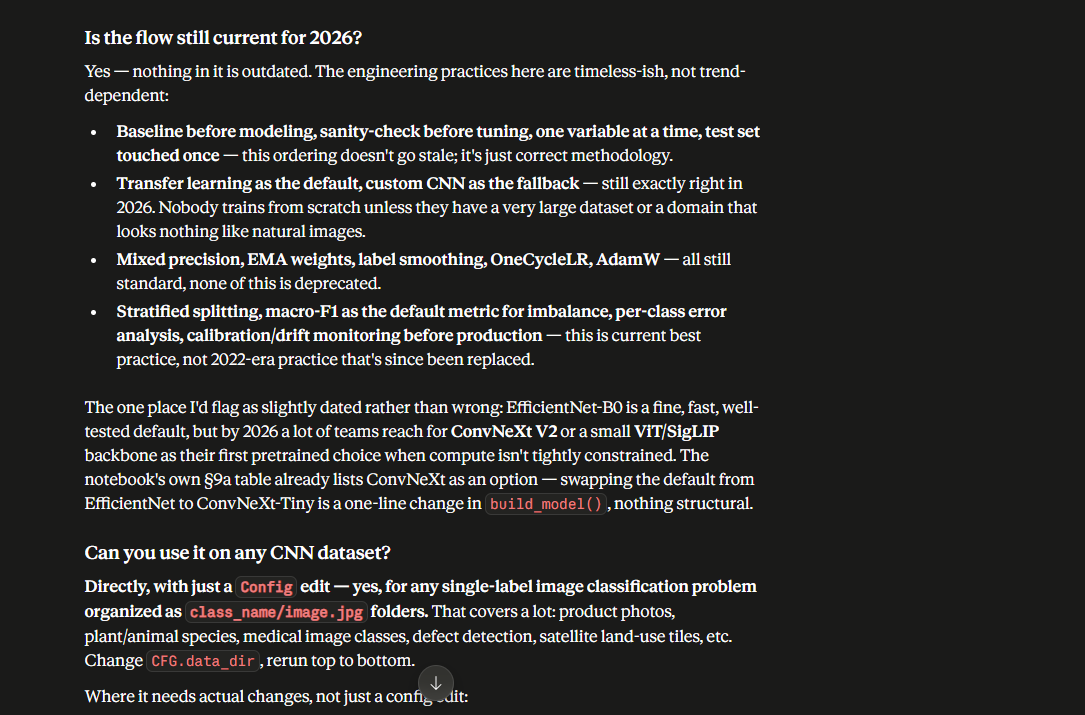

# The Universal CNN Template (2026 Edition)
### An end-to-end walkthrough for any image classification problem — narrated like we're actually building it

This isn't a reference doc, it's a build log. Each step exists because skipping it bit
someone before — so we're not skipping any of them, even the ones that feel obvious.

```
Data                     Baseline                  Model
────                     ────────                  ─────
Understand problem   →   Majority-class floor   →   Transfer learning (default)
Explore (EDA)             +                            ↓
Split (stratified)    Zero-fine-tune number       Feature extraction /
Dataset + loaders          ↓                       partial / full fine-tune
Preprocess             Beats chance?                   ↓
Augment                 ├── No  → back to data     Sanity check (overfit 1 batch)
                         └── Yes → continue              ↓
                                                     Train → Tune → Evaluate once
                                                          ↓
                                                     Save → Infer → Deploy
```

Want to point this at your own dataset? Change the `Config` cell in Step 1 — everything
downstream is generic enough to just work.

**Four things we never do, no matter how tempting:**
1. Build a custom CNN first. Start pretrained (Step 9), fall back only if it underperforms.
2. Tune hyperparameters on a model we haven't sanity-checked (Step 8 first, always).
3. Tune before the data is actually clean and split (Steps 1-6 first).
4. Trust a baseline that's sitting at random chance — that's a data problem, not Step 13's job.


---
## 1. What are we actually trying to predict, and how will we know if it worked?

Before writing a single line of code, we need to answer this stuff — mostly because if we
don't decide our success metric *now*, we'll be tempted to pick whichever metric makes the
final model look best. That defeats the whole point of having one.

- **What exactly are we predicting?** One label per image, or several? Are the classes mutually exclusive?
- **Where did this data come from, who labeled it?** Careful expert labels vs. scraped/weak labels changes how much we should trust a "wrong" prediction later.
- **What's the success metric, and why that one?** Plain accuracy only makes sense if classes are roughly balanced. If they're not, macro-F1 or per-class recall is probably the real target — decide this *before* seeing results, not after.
- **What does "good enough" actually look like?** A real number, tied to the real use case ("95% precision on the positive class, because false positives are expensive here").

Jot the answers down somewhere at the top of your own project. Future-you will not remember.


In [ ]:
import os
import json
import random
import time
from pathlib import Path
from datetime import datetime
from typing import Optional

import numpy as np
import torch
import torch.nn as nn
import torchvision
from torch.utils.data import Dataset, DataLoader

In [ ]:
def set_seed(seed: int = 42) -> None:
  """Fix random seeds so re-running this notebook gives the same numbers twice."""
  random.seed(seed)
  np.random.seed(seed)
  torch.manual_seed(seed)
  torch.cuda.manual_seed_all(seed)


set_seed(42)

In [ ]:
# Setup device-agnostic code
device = (
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
device

In [ ]:
torch.__version__

In [ ]:
!nvidia-smi

One constant we'll reuse a bunch of times: EfficientNet-B0's classifier head expects
`1280` input features. Naming it once here means Steps 7, 8, and 9 all reference the same
constant instead of three copies of the literal `1280` quietly drifting apart.

In [ ]:
EFFICIENTNET_B0_FEATURES = 1280

### Config

Every adjustable value lives here, nowhere else. This is what makes Step 13 (tuning)
manageable later — each experiment is just a different version of this one class, so we
always know exactly what we changed between runs.

In [ ]:
class Config:
  # --- Data ---
  data_dir = Path("data/pizza_steak_sushi")   # a single folder of class_name/image.jpg subfolders
  image_size = 224                             # standard for most pretrained models
  val_split = 0.15
  test_split = 0.15                            # set to 0 if you only want train/val
  batch_size = 32
  num_workers = os.cpu_count() // 2 or 1

  # --- Success metric (Step 1 decision) ---
  primary_metric = "macro_f1"                  # "accuracy" is fine only if classes are balanced

  # --- Training ---
  max_epochs = 15
  learning_rate = 1e-3
  weight_decay = 1e-2
  label_smoothing = 0.1
  early_stopping_patience = 4
  seed = 42

  # --- Paths ---
  model_save_dir = Path("models")
  log_dir = Path("runs")

In [ ]:
CFG = Config()
CFG.model_save_dir.mkdir(parents=True, exist_ok=True)
CFG.log_dir.mkdir(parents=True, exist_ok=True)

In [ ]:
# quick gut check -- does this path actually point where we think it does?
CFG.data_dir.exists(), list(CFG.data_dir.iterdir())[:3]

One more thing before we start exploring: a single source of truth for "what counts as
an image." We'll reuse this everywhere below, so the EDA counts, the corruption check, and
the actual train/val/test split can never quietly disagree with each other.

In [ ]:
IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png")


def list_images(directory: Path, recursive: bool = False) -> list[Path]:
  """List image files in a directory, matching IMAGE_EXTENSIONS.

  recursive=True walks the full tree (data_dir/*/*.jpg) -- use for whole-dataset scans.
  recursive=False lists only direct children -- use for a single class folder.
  """
  paths = directory.rglob("*") if recursive else directory.iterdir()
  return sorted(p for p in paths if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS)

---
## 2. Becoming one with the data

Before anything gets built, we just... look at the data. Visually inspecting images and
counting files doesn't teach the *model* anything -- it teaches *us* something, which is
different from computing numbers the pipeline will later depend on (like normalization
stats -- that has to wait for Step 5, after we've split off a training set).

Three things worth checking here: class balance, corrupted files, and what the images
actually look like.

In [ ]:
def walk_through_dir(dir_path: Path) -> None:
  """Prints image counts per class folder -- fastest way to spot imbalance."""
  for class_dir in sorted(p for p in dir_path.iterdir() if p.is_dir()):
    num_images = len(list_images(class_dir, recursive=False))
    if num_images:
      print(f"{class_dir}: {num_images} images")

In [ ]:
walk_through_dir(CFG.data_dir)

**Is the data balanced?** If one class has way more images than another, plain accuracy
gets misleading fast -- a model that always guesses the majority class can still score high
on it. That's exactly why `primary_metric` defaults to `macro_f1` above: it weighs every
class equally, regardless of how many examples it has. Only switch to plain accuracy if the
counts above come back roughly even.

In [ ]:
from PIL import Image, UnidentifiedImageError


def check_for_corrupted_images(data_dir: Path) -> list[Path]:
  """Tries opening every image, reports any that fail.

  Why now: a corrupted file crashes training hours in, at a random batch, with a
  confusing stack trace. Catching it now costs seconds.
  """
  bad_files = []
  all_paths = list_images(data_dir, recursive=True)

  # 1. Try to open + verify every image
  for path in all_paths:
    try:
      with Image.open(path) as img:
        img.verify()
    except (UnidentifiedImageError, OSError):
      bad_files.append(path)

  # 2. Report what we found
  print(f"[INFO] Checked {len(all_paths)} images, found {len(bad_files)} corrupted.")
  return bad_files

In [ ]:
corrupted_files = check_for_corrupted_images(CFG.data_dir)

In [ ]:
corrupted_files
# if this isn't empty, remove or replace those files before continuing

In [ ]:
import matplotlib.pyplot as plt


def show_image_grid(data_dir: Path, images_per_class: int = 3, seed: int = 42) -> None:
  """Shows a few example images from every class, side by side.

  Grid by class (not random images) so we actually catch mislabeled folders,
  surprise-grayscale images, or a class that looks nothing like its name suggests.
  """
  random.seed(seed)
  class_dirs = sorted(d for d in data_dir.iterdir() if d.is_dir())

  fig, axes = plt.subplots(len(class_dirs), images_per_class,
                            figsize=(3 * images_per_class, 3 * len(class_dirs)))

  for row, class_dir in enumerate(class_dirs):
    image_paths = list_images(class_dir, recursive=False)
    sample_paths = random.sample(image_paths, k=min(images_per_class, len(image_paths)))

    for col, path in enumerate(sample_paths):
      ax = axes[row, col] if len(class_dirs) > 1 else axes[col]
      with Image.open(path) as img:
        ax.imshow(img)
        ax.set_title(f"{class_dir.name}", fontsize=10)
        ax.axis("off")

  plt.tight_layout()
  plt.show()

In [ ]:
show_image_grid(CFG.data_dir)

**One more thing worth a thought -- duplicates.** Near-duplicate images (burst-mode
photos, the same picture scraped twice) can land in different splits later and let the
model "cheat" by half-remembering something it technically saw in training. If this data
was scraped or pulled from video frames, a quick perceptual-hash pass (the `imagehash`
package) before splitting is worth it. For a clean, curated dataset like this one, it's
usually not worth the extra step -- use your judgment based on where the data came from.

Nothing above is a hard blocker on its own -- loaded, counted, checked for corruption,
looked at. On to splitting the data.

---
## 3. Splitting the data, before anything else touches it

Why so early, before loading or preprocessing anything? Every step from here on risks
**data leakage** -- info from data the model shouldn't see, sneaking into training. The
only reliable fix is to physically separate the splits *first*, then make every later
decision (normalization stats, augmentation strength) using only the training slice.

**Why stratified and not plain random?** A plain random split can accidentally shift class
proportions between train/val/test, especially on a small dataset. Stratifying keeps the
same ratio in every split, so val/test numbers are trustworthy reflections of real
performance instead of an unlucky split.

The split itself happens in two numbered steps below (matching the two numbered
comments in the code that follows):
1. Split off the test set first, from the full dataset.
2. Split what's left into train and val.

**Do we need train/val/test, or just train/val?** With enough data (roughly 500+ images
per class) use all three -- the held-out test set is what makes the final number
trustworthy. With very little data, train/val is more practical, but then the "final"
number is honestly a validation number, not a true test number.

In [ ]:
from sklearn.model_selection import train_test_split


def build_stratified_split(
  data_dir: Path, val_split: float, test_split: float, seed: int
) -> tuple[tuple[list[Path], list[str]], tuple[list[Path], list[str]],
           tuple[list[Path], list[str]], list[str]]:
  """Returns file paths and labels for train/val/test, class proportions preserved."""
  all_paths, all_labels = [], []
  class_names = sorted(d.name for d in data_dir.iterdir() if d.is_dir())

  for class_name in class_names:
    class_paths = list_images(data_dir / class_name, recursive=False)
    all_paths.extend(class_paths)
    all_labels.extend([class_name] * len(class_paths))

  # 1. Split off the test set first
  train_val_paths, test_paths, train_val_labels, test_labels = train_test_split(
    all_paths, all_labels, test_size=test_split, stratify=all_labels, random_state=seed
  )
  # 2. Then split what's left into train / val
  relative_val_size = val_split / (1 - test_split)
  train_paths, val_paths, train_labels, val_labels = train_test_split(
    train_val_paths, train_val_labels, test_size=relative_val_size,
    stratify=train_val_labels, random_state=seed
  )

  return (train_paths, train_labels), (val_paths, val_labels), (test_paths, test_labels), class_names

In [ ]:
(train_paths, train_labels), (val_paths, val_labels), (test_paths, test_labels), class_names = \
    build_stratified_split(CFG.data_dir, CFG.val_split, CFG.test_split, CFG.seed)

In [ ]:
len(train_paths), len(val_paths), len(test_paths)
# expect roughly the same class ratio as the full dataset in each -- that's the whole point of stratifying

In [ ]:
class_names

In [ ]:
class_to_idx = {name: idx for idx, name in enumerate(class_names)}

In [ ]:
class_to_idx

Split's done and frozen -- stratified, proportions preserved, `class_to_idx` built
from the same `class_names` everything downstream will use. On to the loading pipeline.

---
## 4. A `Dataset`, so PyTorch actually knows how to read this

A network doesn't take a folder of JPEGs -- it takes tensors, in batches, on the right
device. [`Dataset`](https://pytorch.org/docs/stable/data.html#torch.utils.data.Dataset) defines how to fetch and label *one* example; [`DataLoader`](https://pytorch.org/docs/stable/data.html#torch.utils.data.DataLoader)
(built after Step 6, once transforms exist) wraps it to handle batching, shuffling, and
parallel loading.

**Why not just use `torchvision.datasets.ImageFolder`?** It expects data physically
arranged into `train/`, `val/`, `test/` folders on disk. We already split the data as file
*lists* in memory (Step 3) -- a custom `Dataset` that takes paths + labels directly is
simpler here, and it's the exact pattern you'd need anyway if labels came from a CSV
instead of folders.

**Why bother with error handling inside `__getitem__`?** Step 2 checked for corrupted
files, but new data added later won't have that guarantee, and a `Dataset` that crashes an
entire run over one bad file is fragile for no good reason.

In [ ]:
class ImageClassificationDataset(Dataset):
  """Loads images from a list of file paths + labels, with error handling for unreadable files."""

  def __init__(
    self,
    paths: list[Path],
    labels: list[str],
    class_to_idx: dict[str, int],
    transform=None,
  ):
    self.paths = paths
    self.labels = labels
    self.class_to_idx = class_to_idx
    self.transform = transform

  def __len__(self) -> int:
    return len(self.paths)

  def __getitem__(self, index: int) -> tuple[torch.Tensor, int]:
    path = self.paths[index]
    label = self.class_to_idx[self.labels[index]]

    try:
      image = Image.open(path).convert("RGB")  # .convert ensures 3 channels even for grayscale input
    except (UnidentifiedImageError, OSError):
      # Falls back to a neighboring sample instead of crashing the whole run.
      # Should be rare if Step 2's corruption check was thorough.
      print(f"[INFO] Could not read {path}, substituting a nearby sample.")
      return self.__getitem__((index + 1) % len(self))

    if self.transform:
      image = self.transform(image)

    return image, label

DataLoaders come later -- each split needs its own transform, and we haven't defined
those yet. That's Steps 5 and 6.

---
## 5. Preprocessing -- turning an image into something the model can actually read

Two parts to this:
- **Resize** -- every image needs the same fixed shape, since the network's first layer
  expects one. `224x224` is the standard size most pretrained models were trained on.
- **Normalize** -- scales pixel values to match what the model was trained on. Skipping
  this doesn't throw an error, it just quietly hurts accuracy.

This is different from augmentation (Step 6): preprocessing happens identically to every
image, every time, including at inference. Augmentation is randomized and training-only.

All of this gets chained together with [`transforms.Compose`](https://pytorch.org/vision/stable/generated/torchvision.transforms.Compose.html), which runs each step in order on every image that passes through it.

**Whose normalization values do we use?**
1. **Using a pretrained model (our default, Step 9)** — use the model's own built-in
   transform (`weights.transforms()`). It was trained with specific values; anything else
   quietly hurts accuracy.
2. **Training a custom CNN from scratch** — compute mean/std from the *training split
   only*. ImageNet stats are a fine fallback if the images look nothing like ImageNet
   (medical scans, say), but your own stats are more accurate once you have enough data.

Computing those stats from anything other than the training split would leak val/test
information into preprocessing -- exactly what Step 3 was trying to prevent.

In [ ]:
from torchvision import transforms


def compute_normalization_stats(
  paths: list[Path], image_size: int, sample_size: int = 500
) -> tuple[list[float], list[float]]:
  """Computes mean/std from a sample of the TRAINING split only. Only needed for from-scratch training."""
  sample_paths = random.sample(paths, k=min(sample_size, len(paths)))
  to_tensor = transforms.Compose([transforms.Resize((image_size, image_size)), transforms.ToTensor()])

  pixel_sum, pixel_sq_sum, num_pixels = 0.0, 0.0, 0
  for path in sample_paths:
    img_tensor = to_tensor(Image.open(path).convert("RGB"))
    pixel_sum += img_tensor.sum(dim=[1, 2])
    pixel_sq_sum += (img_tensor ** 2).sum(dim=[1, 2])
    num_pixels += img_tensor.shape[1] * img_tensor.shape[2]

  mean = pixel_sum / num_pixels
  std = ((pixel_sq_sum / num_pixels) - mean ** 2).sqrt()
  return mean.tolist(), std.tolist()


# only relevant if training a custom CNN from scratch (Step 9's fallback) --
# custom_mean, custom_std = compute_normalization_stats(train_paths, CFG.image_size)

In [ ]:
# our default: pretrained model, so we use the standard ImageNet stats it was trained with
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

---
## 6. Augmentation -- but only on data the model actually trains on

Augmentation's job is to make training a bit harder, in a *useful* way, so the model
learns robust patterns instead of memorizing exact pixels. Val and test exist to answer
"how does this model do on real, unmodified images?" -- augmenting them would just be
answering a different, less useful question.

**How much augmentation do we actually need?**
1. **Small dataset (hundreds to low-thousands per class)** — `RandAugment`, a strong,
   pre-tuned auto-augmentation policy. Adds real variety without hand-picking transforms.
2. **Large dataset (tens of thousands+ per class)** — plain flip + light rotation/color
   jitter is usually enough; the data itself already provides variety.

*(Worth knowing: Mixup/CutMix blend two images and their labels together — a different,
complementary trick to RandAugment. Standard in a lot of 2026 recipes for small-to-medium
data, via `torchvision.transforms.v2.MixUp`/`CutMix`. We're treating it as an optional
upgrade here, not a default — reach for it if simpler augmentation still isn't enough.)*

**A few easy ways to get this wrong:**
- Augmenting the val/test transform (only `train_transform` should have randomness)
- Normalizing with stats computed from val/test data (leaks info -- see Step 5)
- Forgetting `.convert("RGB")`, letting a grayscale image silently break channel counts
- Shuffling the val/test `DataLoader` (makes runs non-reproducible for no benefit)

In [ ]:
# preprocessing + augmentation, training data only
train_transform = transforms.Compose([
    transforms.Resize((CFG.image_size, CFG.image_size)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandAugment(num_ops=2, magnitude=9),   # strong default for small datasets
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

In [ ]:
# preprocessing ONLY, no randomness -- for val and test
eval_transform = transforms.Compose([
    transforms.Resize((CFG.image_size, CFG.image_size)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

Now that both transforms exist, we can finally build the three `Dataset`s from Step 4.

In [ ]:
train_dataset = ImageClassificationDataset(train_paths, train_labels, class_to_idx, transform=train_transform)
val_dataset = ImageClassificationDataset(val_paths, val_labels, class_to_idx, transform=eval_transform)
test_dataset = ImageClassificationDataset(test_paths, test_labels, class_to_idx, transform=eval_transform)

In [ ]:
len(train_dataset), len(val_dataset), len(test_dataset)
# should match Step 3's split counts exactly

In [ ]:
loader_kwargs = dict(
    batch_size=CFG.batch_size,
    num_workers=CFG.num_workers,
    pin_memory=True,           # speeds up the CPU -> GPU transfer
    persistent_workers=CFG.num_workers > 0,   # keeps workers alive between epochs instead of restarting them
)

In [ ]:
train_loader = DataLoader(train_dataset, shuffle=True, **loader_kwargs)
val_loader = DataLoader(val_dataset, shuffle=False, **loader_kwargs)
test_loader = DataLoader(test_dataset, shuffle=False, **loader_kwargs)

In [ ]:
# sanity check before moving on -- do the shapes actually make sense?
images, labels = next(iter(train_loader))
images.shape  # [batch, channels, height, width]

---
## 7. The number everything else has to beat

Two baselines, because they answer two different questions:
- **Majority-class predictor** (always guess the most common class) -- the absolute floor.
  Any real model needs to clear this by a real margin or it isn't learning anything.
- **Zero-fine-tune pretrained model** (frozen backbone, untrained new head, zero training
  steps) -- tells us how much the pretrained features alone are worth, before we've spent
  any training time.

Both take seconds to compute. No excuse to skip either before committing to a full run.

In [ ]:
from collections import Counter


def majority_class_baseline(labels: list[str], class_names: list[str]) -> float:
  """Accuracy if we always predict the most common class -- the floor to beat."""
  most_common_class, count = Counter(labels).most_common(1)[0]
  accuracy = count / len(labels)
  print(f"[INFO] Majority-class baseline: always predict '{most_common_class}' -> {accuracy:.2%} accuracy")
  return accuracy

In [ ]:
majority_baseline_acc = majority_class_baseline(train_labels, class_names)

In [ ]:
def zero_fine_tune_baseline(class_names: list[str], val_loader: DataLoader, device: str) -> float:
  """Frozen pretrained backbone, untrained head, zero training steps. Tests raw pretrained features."""
  # New method of loading pretrained weights (torchvision v0.13+)
  weights = torchvision.models.EfficientNet_B0_Weights.DEFAULT
  model = torchvision.models.efficientnet_b0(weights=weights).to(device)
  # Old method, pre-v0.13, in case you're on an older torchvision:
  # model = torchvision.models.efficientnet_b0(pretrained=True).to(device)

  # Freeze the backbone, swap in an untrained head
  for param in model.features.parameters():
    param.requires_grad = False
  model.classifier = nn.Linear(EFFICIENTNET_B0_FEATURES, len(class_names)).to(device)

  # Run it over val, zero training steps taken
  model.eval()
  correct, total = 0, 0
  with torch.inference_mode():
    for images, labels in val_loader:
      images, labels = images.to(device), labels.to(device)
      preds = model(images).argmax(dim=1)
      correct += (preds == labels).sum().item()
      total += len(labels)

  accuracy = correct / total
  print(f"[INFO] Zero-fine-tune baseline: {accuracy:.2%} accuracy (expect close to random -- head is untrained)")
  return accuracy

In [ ]:
zero_shot_baseline_acc = zero_fine_tune_baseline(class_names, val_loader, device)

**Is this a modeling problem or a data problem?** We've now got two numbers: random
chance, and what a model that already knows edges, textures, and shapes from millions of
images scores with *zero* training. If that pretrained model can't beat random guessing,
the question isn't "which architecture next" -- it's "why can't a model that already knows
how to see, see this." That's basically never answered by a bigger model. It's answered by
going back and looking at the data again.

Worth saying plainly: never tune a model before verifying the dataset. Bad labels
usually cost more accuracy than a bad architecture choice ever will, and no amount of
architecture searching fixes a wrong label. So the rule here is simple -- if the baseline
sits at chance level, stop and go back to Steps 2-6.

In [ ]:
random_chance_accuracy = 1 / len(class_names)
random_chance_accuracy, zero_shot_baseline_acc

In [ ]:
# a generous margin above random chance -- if we're not even clearing this, something upstream is broken
if zero_shot_baseline_acc < random_chance_accuracy * 1.5:
    print(
        "STOP: baseline is at or near random chance.\n"
        "This is very likely a DATA problem, not a modeling problem. Before going further, revisit:\n"
        "  - Step 2 (EDA): are labels correct? are classes visually distinguishable at all?\n"
        "  - Step 3 (Split): did stratification actually preserve class balance?\n"
        "  - Step 4-5 (Dataset/Preprocessing): are images and labels aligned correctly?\n"
        "Do NOT proceed to Step 8 until this clears random chance by a healthy margin."
    )
else:
    print("Baseline clears random chance -- safe to move on to Step 8 (sanity check).")

> **Checkpoint**
> - [x] Majority-class floor computed
> - [x] Zero-fine-tune baseline computed
> - [x] Baseline clears random chance by a healthy margin
>
> On to the pipeline sanity check.

---
## 8. Sanity check -- can the model even memorize one batch?

If it *can't*, something in the pipeline is broken -- a labels/images mismatch, a layer
that's frozen when it shouldn't be, a learning rate that's effectively zero, a loss
function bug. Bugs like these are far easier to spot on one batch in 30 seconds than
after a 2-hour training run that just... didn't learn.

**What success looks like:** loss should drop close to zero and accuracy should hit ~100%
on that one batch within a couple hundred steps. If it doesn't, stop and debug right here.

In [ ]:
def overfit_single_batch(
  model, images: torch.Tensor, labels: torch.Tensor, device: str,
  steps: int = 200, lr: float = 1e-3,
) -> tuple[float, float]:
  """Trains repeatedly on one batch only. If the model can't memorize it, something's broken."""
  model.train()
  images, labels = images.to(device), labels.to(device)
  optimizer = torch.optim.Adam(model.parameters(), lr=lr)
  loss_fn = nn.CrossEntropyLoss()

  for step in range(steps):
    # 1. Forward pass
    preds = model(images)
    loss = loss_fn(preds, labels)

    # 2. Optimizer zero grad, backward, step
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    # 3. Print progress every 50 steps
    if step % 50 == 0 or step == steps - 1:
      accuracy = (preds.argmax(dim=1) == labels).float().mean().item()
      print(f"Step {step}: loss={loss.item():.4f}, accuracy={accuracy:.2%}")

  return loss.item(), accuracy

In [ ]:
# build the model we're actually testing (see Step 9 for why this architecture)
sanity_model = torchvision.models.efficientnet_b0(
    weights=torchvision.models.EfficientNet_B0_Weights.DEFAULT
).to(device)
sanity_model.classifier = nn.Linear(EFFICIENTNET_B0_FEATURES, len(class_names)).to(device)

In [ ]:
sample_images, sample_labels = next(iter(train_loader))

In [ ]:
final_loss, final_acc = overfit_single_batch(sanity_model, sample_images, sample_labels, device)
final_loss, final_acc

In [ ]:
assert final_acc > 0.95, "Model failed to overfit a single batch -- stop and debug the pipeline before continuing."
print("Sanity check passed: pipeline is working correctly.")

In [ ]:
# same shape check as Step 8's sanity run, just re-confirming now that model_0 is the real one
model_0(sample_images.to(device)).shape

---
## 9. Which architecture do we actually start with?

Could train from scratch. A from-scratch CNN has to learn edges, textures, and shapes
from nothing, using only this dataset -- way more data and training time needed to reach
the same accuracy. A pretrained backbone already knows those low-level features from
millions of images; we're only asking it to adapt the last layers to our classes. For the
overwhelming majority of image classification problems, that's just the faster, more
accurate path. So: transfer learning first, using torchvision's
[pretrained EfficientNet weights](https://pytorch.org/vision/stable/models/efficientnet.html). We only fall back to a custom CNN if it
genuinely underperforms the Step 7 baseline.

**How much of the pretrained model should actually be unfrozen?**
1. **Small dataset (hundreds/class)** — feature extraction: freeze the whole backbone,
   train only the new classifier head. Least overfitting risk, fastest to train.
2. **Medium dataset (low-thousands/class)** — partial fine-tuning: freeze early layers,
   unfreeze the last few blocks. Early layers hold generic features worth keeping.
3. **Large dataset (tens of thousands+/class)** — full fine-tuning: unfreeze everything,
   small learning rate. Enough data to safely adapt every layer.

We're working with a small dataset here, so: feature extraction.

In [ ]:
def build_model(num_classes: int, unfreeze_last_n_blocks: int = 0) -> nn.Module:
  """Builds an EfficientNet-B0 with a configurable unfreeze strategy.

  unfreeze_last_n_blocks=0  -> feature extraction (small datasets)
  unfreeze_last_n_blocks>0  -> partial fine-tuning (medium datasets)
  """
  weights = torchvision.models.EfficientNet_B0_Weights.DEFAULT
  model = torchvision.models.efficientnet_b0(weights=weights)

  # Freeze everything first
  for param in model.features.parameters():
    param.requires_grad = False

  # Then selectively unfreeze the last N blocks
  if unfreeze_last_n_blocks > 0:
    for block in list(model.features.children())[-unfreeze_last_n_blocks:]:
      for param in block.parameters():
        param.requires_grad = True

  # Swap in a fresh head sized for our classes
  model.classifier = nn.Sequential(
    nn.Dropout(p=0.2, inplace=True),
    nn.Linear(in_features=EFFICIENTNET_B0_FEATURES, out_features=num_classes),
  )

  return model.to(device)

In [ ]:
# small dataset -> feature extraction. Kept as a named variable (not a bare literal) so
# Step 15 can save it and Step 16 can rebuild the exact same architecture later.
UNFREEZE_LAST_N_BLOCKS = 0
model_0 = build_model(num_classes=len(class_names), unfreeze_last_n_blocks=UNFREEZE_LAST_N_BLOCKS)

In [ ]:
trainable = sum(p.numel() for p in model_0.parameters() if p.requires_grad)
total = sum(p.numel() for p in model_0.parameters())
trainable, total
# trainable should be small relative to total -- if most of the network is trainable
# on a small dataset, that's a sign to freeze more, not a sign the model needs to be bigger

### 9b. Option 2: a custom CNN from scratch (the fallback)

Step 9 picked **Option 1: transfer learning** (`model_0`) as the default. Mentioning a
fallback without writing it isn't really a fallback -- so here's **Option 2**: `model_1`,
a small TinyVGG-style CNN, built the same way you'd build one for any dataset where
transfer learning underperforms.

Pros of Option 2: no dependency on pretrained weights, full control over every layer,
works even if your images look nothing like ImageNet (e.g. spectrograms, satellite
bands).
Cons: needs far more data and training time to reach the same accuracy Option 1 gets
almost for free -- which is exactly why it's the fallback, not the default.

- `nn.Conv2d` slides a small filter across the image to pick up local patterns (edges,
  textures). Stack a few and later layers start detecting more complex shapes built out of
  simpler ones.
- `nn.MaxPool2d` shrinks the spatial size after each block -- less computation, and more
  tolerance for a feature appearing in a slightly different position.
- `nn.BatchNorm2d` stabilizes training by normalizing activations between layers --
  genuinely useful from scratch; a pretrained model doesn't need it since its weights are
  already in a stable range.

**When to actually switch to this:** only if `model_0`, after real tuning (Step 13), still
doesn't beat the Step 7 baseline by a meaningful margin.

In [ ]:
class CustomCNN(nn.Module):
  """A small CNN trained from scratch. Use only if transfer learning (model_0) underperforms."""

  def __init__(self, input_channels: int, num_classes: int, hidden_units: int = 32):
    super().__init__()
    self.conv_block_1 = nn.Sequential(
      nn.Conv2d(input_channels, hidden_units, kernel_size=3, padding=1),
      nn.BatchNorm2d(hidden_units),
      nn.ReLU(),
      nn.Conv2d(hidden_units, hidden_units, kernel_size=3, padding=1),
      nn.BatchNorm2d(hidden_units),
      nn.ReLU(),
      nn.MaxPool2d(kernel_size=2),
    )
    self.conv_block_2 = nn.Sequential(
      nn.Conv2d(hidden_units, hidden_units * 2, kernel_size=3, padding=1),
      nn.BatchNorm2d(hidden_units * 2),
      nn.ReLU(),
      nn.Conv2d(hidden_units * 2, hidden_units * 2, kernel_size=3, padding=1),
      nn.BatchNorm2d(hidden_units * 2),
      nn.ReLU(),
      nn.MaxPool2d(kernel_size=2),
    )
    self.conv_block_3 = nn.Sequential(
      nn.Conv2d(hidden_units * 2, hidden_units * 4, kernel_size=3, padding=1),
      nn.BatchNorm2d(hidden_units * 4),
      nn.ReLU(),
      nn.MaxPool2d(kernel_size=2),
    )
    self.classifier = nn.Sequential(
      nn.AdaptiveAvgPool2d(output_size=1),  # collapses to a fixed size regardless of input resolution
      nn.Flatten(),
      nn.Dropout(p=0.3),
      nn.Linear(hidden_units * 4, num_classes),
    )

  def forward(self, x: torch.Tensor) -> torch.Tensor:
    x = self.conv_block_1(x)
    x = self.conv_block_2(x)
    x = self.conv_block_3(x)
    return self.classifier(x)

In [ ]:
# not used by default -- kept ready in case transfer learning underperforms the baseline
# model_1 = CustomCNN(input_channels=3, num_classes=len(class_names)).to(device)

### 9a. If you're picking a different pretrained backbone

The table above covers *how much* of a pretrained model to unfreeze. This is about *which*
one to start from in the first place -- a separate axis, decided once, before the table above
even applies.

| Architecture | Params (base) | Speed | Accuracy tier | Best for |
|---|---|---|---|---|
| **MobileNetV3/V4** | ~3-6M | Fastest | Good, not top-tier | edge / mobile deployment |
| **EfficientNet (B0-B7)** | ~5M-66M | Fast at B0 | Best accuracy-per-FLOP | general default (this notebook uses B0) |
| **ResNet (18-152)** | ~11M-60M | Moderate | Good, below EfficientNet at equal params | legacy compatibility, most tutorial support |
| **ConvNeXt (Tiny-XL)** | ~28M-350M | Slower | Best pure-CNN accuracy | when compute isn't the constraint |

**The actual decision rule:**
- Deploying to a phone/browser/embedded device? Start with MobileNet.
- No deployment constraint? Start with EfficientNet-B0 (what we're doing here).
- Maximum accuracy, compute isn't a concern? ConvNeXt.
- Need to match an existing pipeline that already uses ResNet? That's a legitimate reason,
  just don't expect it to be the most *accurate* option.

Swapping architectures only means changing `build_model`'s `torchvision.models.<name>` call
and the `in_features` on the new classifier head -- everything else here works unchanged.

---
## 10. The training loop itself

We build the loop before picking hyperparameters on purpose -- `train_step` and `test_step`
take loss/optimizer/scheduler as *arguments*, not hardcoded values. That keeps "how
training works" and "what values we train with" as two separate decisions. And the loop
was already exercised once, in miniature, by Step 8's sanity check.

Three things worth explaining before the code:
- **Mixed precision** -- 16-bit floats for most of the pass (32-bit master weights),
  via [`torch.autocast`](https://pytorch.org/docs/stable/amp.html) and
  [`GradScaler`](https://pytorch.org/docs/stable/amp.html#torch.amp.GradScaler) --
  roughly halves memory and often speeds things up, basically no accuracy cost. Standard by now, not an "advanced" trick.
- **Gradient clipping** -- caps how large one weight update can be, so a single unstable
  batch can't throw training off course. Cheap insurance.
- **EMA (Exponential Moving Average) weights** -- a slowly-updated, smoothed copy of the
  weights alongside the actively-trained ones. Tends to generalize slightly better since it
  averages out noisy per-batch fluctuations. We save both (Step 15) and typically use the
  EMA copy at inference.

In [ ]:
class EMA:
  """Maintains a slowly-updated, smoothed copy of the model's weights."""

  def __init__(self, model: nn.Module, decay: float = 0.999):
    self.decay = decay
    self.shadow = {name: param.clone().detach() for name, param in model.state_dict().items()}

  def update(self, model: nn.Module) -> None:
    for name, param in model.state_dict().items():
      if param.dtype.is_floating_point:
        self.shadow[name] = self.decay * self.shadow[name] + (1 - self.decay) * param.detach()
      else:
        self.shadow[name] = param.detach().clone()

  def state_dict(self) -> dict[str, torch.Tensor]:
    return self.shadow

In [ ]:
def train_step(
  model: nn.Module,
  dataloader: DataLoader,
  loss_fn: nn.Module,
  optimizer: torch.optim.Optimizer,
  scheduler,
  scaler: torch.amp.GradScaler,
  ema: EMA,
  device: str,
  grad_clip_norm: float = 1.0,
) -> tuple[float, float]:
  """One pass over the training data, with mixed precision, gradient clipping, and EMA updates."""
  # Put the model in train mode
  model.train()
  total_loss, total_correct, total_samples = 0.0, 0, 0

  # Loop through data loader data batches
  for images, labels in dataloader:
    # Send data to the target device
    images, labels = images.to(device), labels.to(device)
    optimizer.zero_grad()

    # 1. Forward pass (mixed precision)
    with torch.autocast(device_type=device if device != "mps" else "cpu", enabled=device == "cuda"):
      preds = model(images)
      loss = loss_fn(preds, labels)

    # 2. Backward pass, scaled
    scaler.scale(loss).backward()
    scaler.unscale_(optimizer)

    # 3. Clip gradients before the optimizer step
    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=grad_clip_norm)

    # 4. Optimizer + scheduler step
    scaler.step(optimizer)
    scaler.update()
    scheduler.step()

    # 5. Update the EMA shadow weights
    ema.update(model)

    # Accumulate metrics
    total_loss += loss.item() * len(labels)
    total_correct += (preds.argmax(dim=1) == labels).sum().item()
    total_samples += len(labels)

  # Adjust metrics to get average loss and accuracy for the epoch
  return total_loss / total_samples, total_correct / total_samples

In [ ]:
def test_step(
  model: nn.Module, dataloader: DataLoader, loss_fn: nn.Module, device: str
) -> tuple[float, float]:
  """One pass over val/test data. No gradient tracking, no weight updates, no augmentation."""
  # Put model in eval mode
  model.eval()
  total_loss, total_correct, total_samples = 0.0, 0, 0

  # Turn on inference mode
  with torch.inference_mode():
    for images, labels in dataloader:
      images, labels = images.to(device), labels.to(device)

      # 1. Forward pass
      preds = model(images)
      loss = loss_fn(preds, labels)

      # Accumulate metrics
      total_loss += loss.item() * len(labels)
      total_correct += (preds.argmax(dim=1) == labels).sum().item()
      total_samples += len(labels)

  return total_loss / total_samples, total_correct / total_samples

---
## 11. Now that the loop works, what values do we actually train with?

The loop exists and is known to work (Step 8 already exercised this code path). Now we
pick the specific values -- a separate decision from *how* the loop works.

**Why [`AdamW`](https://pytorch.org/docs/stable/generated/torch.optim.AdamW.html), not SGD?** SGD with momentum can eke out slightly better final accuracy on
some problems, but needs careful LR tuning to get there. AdamW converges reliably with much
less tuning, which matters most on a dataset we haven't trained on before. Start with
AdamW; only compare against SGD later if generalization becomes the actual bottleneck.

**Why `label_smoothing=0.1`?** Softens the training targets (not "100% confident this is
class A," more like ~90%), which reduces overconfidence and tends to improve both accuracy
and calibration -- close to a free upgrade.

**Why [`OneCycleLR`](https://pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.OneCycleLR.html) instead of a constant learning rate?** Ramping the LR up then back down
over training tends to reach a better final accuracy for very little extra setup. A
constant LR is the simpler fallback if `OneCycleLR` ever behaves unexpectedly.

In [ ]:
loss_fn = nn.CrossEntropyLoss(label_smoothing=CFG.label_smoothing)

In [ ]:
# only the trainable params -- everything we froze in build_model() stays frozen here too
trainable_params = [p for p in model_0.parameters() if p.requires_grad]
optimizer = torch.optim.AdamW(trainable_params, lr=CFG.learning_rate, weight_decay=CFG.weight_decay)

In [ ]:
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer,
    max_lr=CFG.learning_rate,
    steps_per_epoch=len(train_loader),
    epochs=CFG.max_epochs,
)

---
## 12. Actually training it

The loop, the loss, the optimizer, and the schedule all exist now. All that's left is to
run it and watch whether it's learning something useful.

**Why checkpoint on the primary metric, not just loss?** Step 1 defined the metric that
actually matters here (`CFG.primary_metric`, macro-F1 by default, for imbalanced data). If
we saved "best" checkpoints by validation loss alone on an imbalanced dataset, we could
save a checkpoint that's great on the majority class and quietly bad on the minority one.

**The rule that doesn't bend:** the test set is never touched in this loop. Every decision
here comes from train/val data only.

In [ ]:
from sklearn.metrics import f1_score


def compute_macro_f1(model: nn.Module, dataloader: DataLoader, device: str) -> float:
  """Macro-averaged F1 over a full pass -- treats every class equally (Step 1's metric decision)."""
  model.eval()
  all_preds, all_labels = [], []
  with torch.inference_mode():
    for images, labels in dataloader:
      preds = model(images.to(device)).argmax(dim=1).cpu()
      all_preds.append(preds)
      all_labels.append(labels)
  return f1_score(torch.cat(all_labels), torch.cat(all_preds), average="macro")

In [ ]:
def train_and_validate(
  model: nn.Module,
  train_loader: DataLoader,
  val_loader: DataLoader,
  loss_fn: nn.Module,
  optimizer: torch.optim.Optimizer,
  scheduler,
  max_epochs: int,
  patience: int,
  device: str,
  checkpoint_path: Path,
):
  # 1. Set up mixed precision, EMA, and a results dictionary
  scaler = torch.amp.GradScaler(enabled=device == "cuda")
  ema = EMA(model)
  history = {"train_loss": [], "val_loss": [], "val_metric": []}
  best_metric, epochs_without_improvement = -float("inf"), 0

  # 2. Loop through training and validation steps for a number of epochs
  for epoch in range(max_epochs):
    train_loss, train_acc = train_step(model, train_loader, loss_fn, optimizer, scheduler, scaler, ema, device)
    val_loss, val_acc = test_step(model, val_loader, loss_fn, device)
    val_metric = compute_macro_f1(model, val_loader, device)

    # 3. Print out what's happening
    print(f"Epoch {epoch+1}/{max_epochs} | train_loss: {train_loss:.4f} | "
          f"val_loss: {val_loss:.4f} | val_acc: {val_acc:.4f} | val_macro_f1: {val_metric:.4f}")
    # print(f"  debug -- lr now: {scheduler.get_last_lr()}")  # left this here, handy when the schedule looks off

    # 4. Update results dictionary
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_metric"].append(val_metric)

    # 5. Save the best checkpoint so far, or count toward early stopping
    if val_metric > best_metric:
      best_metric = val_metric
      epochs_without_improvement = 0
      torch.save({
        "model_state_dict": model.state_dict(),
        "ema_state_dict": ema.state_dict(),
        "epoch": epoch,
        "val_metric": val_metric,
      }, checkpoint_path)
      print(f"  New best model saved (val_macro_f1: {val_metric:.4f})")
    else:
      epochs_without_improvement += 1
      if epochs_without_improvement >= patience:
        print(f"Early stopping: no improvement for {patience} epochs.")
        break

  # 6. Return the filled results (and the EMA object, for its final shadow weights)
  return history, ema

In [ ]:
checkpoint_path = CFG.model_save_dir / "best_checkpoint.pth"

In [ ]:
history, ema = train_and_validate(
    model=model_0,
    train_loader=train_loader,
    val_loader=val_loader,
    loss_fn=loss_fn,
    optimizer=optimizer,
    scheduler=scheduler,
    max_epochs=CFG.max_epochs,
    patience=CFG.early_stopping_patience,
    device=device,
    checkpoint_path=checkpoint_path,
)

In [ ]:
def plot_training_history(history: dict[str, list[float]]) -> None:
  """Plots training/val loss and val macro-F1 curves."""
  fig, axes = plt.subplots(1, 2, figsize=(12, 4))
  axes[0].plot(history["train_loss"], label="train_loss")
  axes[0].plot(history["val_loss"], label="val_loss")
  axes[0].set_title("Loss")
  axes[0].set_xlabel("Epoch")
  axes[0].legend()

  axes[1].plot(history["val_metric"], label="val_macro_f1", color="green")
  axes[1].set_title("Validation macro-F1")
  axes[1].set_xlabel("Epoch")
  axes[1].legend()

  plt.tight_layout()
  plt.show()

In [ ]:
plot_training_history(history)

**Reading the curves:**

| Pattern | Meaning | What to do |
|---|---|---|
| Train and val loss drop together, val metric climbs and flattens | Good fit | On to Step 13/14 |
| Train loss keeps dropping, val loss rises | Overfitting | More augmentation, more dropout, freeze more layers |
| Both losses stay high, metric stays low | Underfitting | Unfreeze more layers, train longer, re-check Step 8 |

> **Checkpoint**
> - [x] Model trained with early stopping
> - [x] Best checkpoint saved by `val_macro_f1`, not loss alone
> - [x] Curves reviewed against the table above
>
> Curves look healthy? Skip to Step 13 or 14. Something look off? Troubleshooting guide is next.

---
## 12a. If something looks off -- a troubleshooting guide

For each symptom below, the causes worth checking, roughly in the order to check them.

### Low validation accuracy -- possible causes

| Symptom | Likely cause | Where to check |
|---|---|---|
| Train accuracy is ALSO low | Underfitting -- see below | Step 12 curves |
| Train accuracy high, val accuracy low | Overfitting -- see below | Step 12 curves |
| BOTH near random-chance | Pipeline bug -- re-check Step 7's gate | Steps 2-6 |
| Val accuracy *higher* than train | Usually not a bug -- train metrics are computed mid-epoch with augmentation on a partially-updated model; val is post-epoch, clean. A small gap this direction is normal | If the gap is large, double check `eval_transform` isn't leaking into training |
| Fine for most classes, very low for one or two | Not global -- see error analysis, Step 14a | Step 14a |

### Overfitting -- fixes, in order of effort

1. **Freeze more of the backbone** (lower `unfreeze_last_n_blocks`) -- highest-leverage fix if you're fine-tuning at all.
2. **Increase augmentation strength**, or add Mixup/CutMix (mentioned in Step 6).
3. **Increase dropout** in the classifier head.
4. **Increase weight decay** (`CFG.weight_decay`).
5. **Get more data**, or shrink the model -- higher-effort, but often the most durable fix.
6. **Tighten early stopping** -- treats the symptom, not the cause, but a fine stopgap.

### Underfitting -- fixes, in order of effort

1. **Unfreeze more of the backbone** -- mirror image of the overfitting fix.
2. **Train longer**, only after confirming (Step 12 curves) both losses are still trending down.
3. **Raise the learning rate**, if loss is falling very slowly rather than plateaued.
4. **Reduce regularization** -- if you inherited a heavily-regularized config from a previous run.
5. **Reconsider the architecture** -- the backbone itself may be too small for this problem; this is also the trigger to reconsider `CustomCNN` (Step 9).
6. **Re-run Step 8's sanity check** -- if none of this fits, something scheduler/freeze/normalization-specific is probably going on.

---
## 13. Tuning -- one variable at a time, or the results mean nothing

If we change learning rate, batch size, and unfreeze depth all at once and results
improve, we won't know which change mattered -- which means we can't repeat the win on the
next project. One variable at a time turns tuning from guesswork into something we
actually learn from.

**Why learning rate first?** Of everything we could tune, it has the largest effect on
final performance, and a badly-chosen one makes every other change look meaningless
(diverging or stuck training won't respond to anything else). Once it's in a good range,
move to batch size/augmentation, then unfreeze depth, then regularization.

**Why bother with an experiment logger?** ([`SummaryWriter`](https://pytorch.org/docs/stable/tensorboard.html) is the built-in option -- Past 2-3 experiments, remembering which config
produced which result stops working. A logger records config + metrics together, so
comparing runs later is a lookup, not a guessing game.

In [ ]:
from torch.utils.tensorboard import SummaryWriter


def create_writer(experiment_name: str, extra: str = None) -> SummaryWriter:
  """Creates a descriptively-named, timestamped TensorBoard writer.

  Swap for wandb.init(...) or mlflow.start_run(...) if you prefer those -- the
  config-in, metrics-out pattern is the same either way.
  """
  timestamp = datetime.now().strftime("%Y-%m-%d_%H-%M")
  log_dir = CFG.log_dir / f"{timestamp}_{experiment_name}"
  if extra:
    log_dir = log_dir / extra
  return SummaryWriter(log_dir=str(log_dir))

In [ ]:
# log this one experiment's config + result, so it's searchable later
writer = create_writer(experiment_name="lr_1e-3_feature_extraction")
writer.add_hparams(
    {"lr": CFG.learning_rate, "unfreeze_blocks": 0, "batch_size": CFG.batch_size},
    {"best_val_macro_f1": max(history["val_metric"])},
)
writer.close()

**A practical tuning checklist, roughly in this order:**
1. **Learning rate** -- sweep a few values (`3e-4`, `1e-3`, `3e-3`) with everything else fixed.
2. **Batch size / augmentation strength** -- bigger batches tolerate a slightly higher LR; heavier augmentation helps most if Step 12's curves showed overfitting.
3. **Unfreeze depth** -- if feature extraction plateaus below target, try partial fine-tuning.
4. **Regularization** -- dropout, weight decay -- only if still overfitting after the above.

**What to leave alone unless you have a specific, observed reason:** optimizer choice
(`AdamW`), scheduler shape (`OneCycleLR`), label smoothing value -- these are well-tested
defaults, and swapping them rarely moves the needle enough to be worth the comparison.

In [ ]:
def lr_sweep(
  build_model_fn,
  num_classes: int,
  train_loader: DataLoader,
  val_loader: DataLoader,
  device: str,
  lrs: tuple[float, ...] = (3e-4, 1e-3, 3e-3),
  probe_epochs: int = 2,
  unfreeze_last_n_blocks: int = 0,
) -> dict[float, float]:
  """Quick LR probe: a couple epochs at each value, compare val macro-F1.

  Not a substitute for full training (Step 12) -- just a cheap way to rule out LRs
  that are obviously too high (diverging) or too low (barely moving).
  """
  results = {}
  for lr in lrs:
    probe_model = build_model_fn(num_classes=num_classes, unfreeze_last_n_blocks=unfreeze_last_n_blocks)
    probe_loss_fn = nn.CrossEntropyLoss(label_smoothing=CFG.label_smoothing)
    probe_params = [p for p in probe_model.parameters() if p.requires_grad]
    probe_optimizer = torch.optim.AdamW(probe_params, lr=lr, weight_decay=CFG.weight_decay)
    probe_scheduler = torch.optim.lr_scheduler.OneCycleLR(
      probe_optimizer, max_lr=lr, steps_per_epoch=len(train_loader), epochs=probe_epochs
    )
    probe_scaler = torch.amp.GradScaler(enabled=device == "cuda")
    probe_ema = EMA(probe_model)

    for _ in range(probe_epochs):
      train_step(probe_model, train_loader, probe_loss_fn, probe_optimizer, probe_scheduler, probe_scaler, probe_ema, device)

    val_metric = compute_macro_f1(probe_model, val_loader, device)
    results[lr] = val_metric
    print(f"lr={lr:.0e}  ->  val_macro_f1 after {probe_epochs} epochs: {val_metric:.4f}")

  return results

In [ ]:
# uncomment to run -- costs a few epochs per LR value
# lr_sweep(build_model, len(class_names), train_loader, val_loader, device)

---
## 14. Final evaluation -- the test set, exactly once

Every time we evaluate on the test set and make a decision based on it (even "let me try
one more tweak"), we're implicitly fitting to it, and it stops being a trustworthy,
unbiased read on real-world performance. All tuning happened on validation data (Step 13).
The test set gets touched here, once, after every decision is already final.

**Why per-class metrics and a
[confusion matrix](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html),
not just one number?** An aggregate metric
can hide a model that's excellent on most classes and quietly failing on one. This is where
we find out if that's happening, and exactly which classes get confused with which.

In [ ]:
# load the best checkpoint saved during training (Step 12) before final evaluation
best_checkpoint = torch.load(checkpoint_path, map_location=device)
model_0.load_state_dict(best_checkpoint["model_state_dict"])

In [ ]:
best_checkpoint["epoch"] + 1, best_checkpoint["val_metric"]

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import numpy as np


def final_test_evaluation(
  model: nn.Module, test_loader: DataLoader, class_names: list[str], device: str
) -> tuple[np.ndarray, np.ndarray]:
  # Put model in eval mode
  model.eval()
  all_preds, all_labels = [], []

  # Loop through the test DataLoader, no gradients
  with torch.inference_mode():
    for images, labels in test_loader:
      preds = model(images.to(device)).argmax(dim=1).cpu()
      all_preds.append(preds)
      all_labels.append(labels)

  all_preds = torch.cat(all_preds).numpy()
  all_labels = torch.cat(all_labels).numpy()

  print(classification_report(all_labels, all_preds, target_names=class_names))
  return all_preds, all_labels

In [ ]:
test_preds, test_labels_arr = final_test_evaluation(model_0, test_loader, class_names, device)

In [ ]:
cm = confusion_matrix(test_labels_arr, test_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", xticklabels=class_names, yticklabels=class_names, cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion matrix (test set)")
plt.show()

### 14a. Error analysis -- what to fix next, not just the score

`classification_report` and the confusion matrix already touch on this, but evaluation and
error analysis are different jobs: evaluation gives the score, error analysis says what to
fix next. This is the difference between a model you ship and a model you merely measured.

**Reading the confusion matrix:** rows are true class, columns are predicted. The diagonal
is what the model got right. A concentrated off-diagonal cell (one class consistently
predicted as another) usually means those two classes look visually similar, or the data
has some mislabeled examples -- worth checking the actual images before assuming it's a
modeling problem. Asymmetric confusion (A→B often, B→A rarely) often points to class
imbalance in training, or one class being visually a subset of the other.

In [ ]:
import pandas as pd


def per_class_breakdown(
  all_labels: np.ndarray, all_preds: np.ndarray, class_names: list[str]
) -> pd.DataFrame:
  """Per-class precision/recall/F1/support, sorted worst-F1-first."""
  report = classification_report(all_labels, all_preds, target_names=class_names, output_dict=True)

  rows = []
  for name in class_names:
    row = {"class": name}
    for metric_name, value in report[name].items():
      row[metric_name] = round(value, 3)
    rows.append(row)

  return pd.DataFrame(rows).sort_values("f1-score")

In [ ]:
breakdown = per_class_breakdown(test_labels_arr, test_preds, class_names)
breakdown

The lowest-F1 class(es) above are where to focus next -- check their confusion-matrix
row for what they're confused with, then look at the actual misclassified images below.

In [ ]:
def show_misclassified_images(
  model: nn.Module,
  dataset,
  class_names: list[str],
  device: str,
  n: int = 9,
  seed: int = 42,
) -> None:
  """Plots a grid of misclassified test images with true vs. predicted labels and confidence."""
  random.seed(seed)
  model.eval()

  # 1. Find every misclassified index in the dataset
  misclassified = []
  with torch.inference_mode():
    for idx in range(len(dataset)):
      image, true_label = dataset[idx]
      probs = torch.softmax(model(image.unsqueeze(0).to(device)), dim=1)
      confidence, pred_label = probs.max(dim=1)
      pred_label, confidence = pred_label.item(), confidence.item()
      if pred_label != true_label:
        misclassified.append((idx, true_label, pred_label, confidence))

  print(f"[INFO] {len(misclassified)} / {len(dataset)} test images misclassified.")
  if not misclassified:
    return

  # 2. Sample a handful and plot them, raw file re-opened so it displays properly
  sample = random.sample(misclassified, k=min(n, len(misclassified)))
  cols = 3
  rows = (len(sample) + cols - 1) // cols
  fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 4 * rows))
  axes = axes.flatten() if len(sample) > 1 else [axes]

  for ax, (idx, true_label, pred_label, confidence) in zip(axes, sample):
    raw_image = Image.open(dataset.paths[idx]).convert("RGB")  # tensor's normalized, raw file isn't
    ax.imshow(raw_image)
    ax.set_title(
      f"true: {class_names[true_label]}\npred: {class_names[pred_label]} ({confidence:.0%})",
      fontsize=10, color="crimson",
    )
    ax.axis("off")

  for ax in axes[len(sample):]:
    ax.axis("off")

  plt.tight_layout()
  plt.show()

In [ ]:
show_misclassified_images(model_0, test_dataset, class_names, device)

---
## 15. Saving the model -- properly, not just "it's in memory"

**Why `state_dict` and not the whole model object?** `state_dict` saves only the learned
weights, which stays portable even if we later refactor the model class. Saving the whole
object ties the file to the exact code that existed when we saved it.

**Why save the EMA weights too?** They (Step 10) often generalize slightly better. We save
the EMA weights *from the same best checkpoint* as the regular weights, not from a freshly
constructed EMA object -- otherwise the "EMA weights" file would just be an unsmoothed
duplicate of the final model.

**Why save architecture config, preprocessing, and the label map alongside it?** A
`state_dict` alone doesn't tell future-us what architecture to build before loading it,
what image size/normalization to preprocess with, or which output index maps to which
class. Without this, the saved weights are close to useless a few months from now.

> **Engineering Note**
> A model that only exists in this notebook's memory doesn't exist. If it isn't on disk
> with its config and label map, it's one kernel restart from gone.

In [ ]:
def save_model_package(
  model: nn.Module,
  ema_state_dict: dict,
  class_to_idx: dict,
  cfg: Config,
  unfreeze_last_n_blocks: int,
  save_dir: Path,
  model_name: str,
) -> None:
  """Saves a model's state_dict, EMA weights, and metadata to a target directory.

  Args:
    model: A target PyTorch model to save.
    ema_state_dict: The EMA shadow weights captured at the best checkpoint.
    class_to_idx: Maps class name -> output index, needed to interpret predictions later.
    cfg: The Config used for this run (image_size, etc. get saved into metadata).
    unfreeze_last_n_blocks: Needed to rebuild the exact trained architecture on reload.
    save_dir: A directory for saving the model to.
    model_name: A filename prefix for the saved model, EMA weights, and metadata.

  Example usage:
    save_model_package(model=model_0, ema_state_dict=best_checkpoint["ema_state_dict"],
                        class_to_idx=class_to_idx, cfg=CFG, unfreeze_last_n_blocks=0,
                        save_dir=CFG.model_save_dir, model_name="food_classifier_v1")
  """
  # Create target directory
  save_dir.mkdir(parents=True, exist_ok=True)

  # Save the model + EMA state_dicts
  torch.save(model.state_dict(), save_dir / f"{model_name}.pth")
  torch.save(ema_state_dict, save_dir / f"{model_name}_ema.pth")

  # Save everything future-us needs to rebuild + preprocess correctly
  metadata = {
    "architecture": "efficientnet_b0",
    "unfreeze_last_n_blocks": unfreeze_last_n_blocks,
    "num_classes": len(class_to_idx),
    "class_to_idx": class_to_idx,
    "image_size": cfg.image_size,
    "normalization_mean": IMAGENET_MEAN,
    "normalization_std": IMAGENET_STD,
    "saved_at": datetime.now().isoformat(),
  }
  with open(save_dir / f"{model_name}_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

  print(f"[INFO] Saved model, EMA weights, and metadata to: {save_dir}")

In [ ]:
# use the EMA weights captured in the BEST checkpoint (Step 14), not a freshly constructed
# EMA object -- keeps the saved EMA weights consistent with the same epoch as the model weights
save_model_package(
    model=model_0,
    ema_state_dict=best_checkpoint["ema_state_dict"],
    class_to_idx=class_to_idx,
    cfg=CFG,
    unfreeze_last_n_blocks=UNFREEZE_LAST_N_BLOCKS,
    save_dir=CFG.model_save_dir,
    model_name="food_classifier_v1",
)

In [ ]:
model_0.classifier
# just eyeballing this after saving -- matches the Dropout+Linear head from build_model()

In [ ]:
def verify_reload(
  model_builder_fn,
  save_dir: Path,
  model_name: str,
  test_loader: DataLoader,
  device: str,
) -> nn.Module:
  """Reloads the saved model from disk and confirms it reproduces a sensible test accuracy.

  The difference between assuming your save worked and actually knowing it did.
  """
  with open(save_dir / f"{model_name}_metadata.json") as f:
    metadata = json.load(f)

  reloaded_model = model_builder_fn(
    num_classes=metadata["num_classes"],
    unfreeze_last_n_blocks=metadata["unfreeze_last_n_blocks"],
  )
  reloaded_model.load_state_dict(torch.load(save_dir / f"{model_name}.pth", map_location=device))

  _, reload_acc = test_step(reloaded_model, test_loader, nn.CrossEntropyLoss(), device)
  print(f"[INFO] Reloaded model test accuracy: {reload_acc:.4f} (compare against Step 14's numbers)")
  return reloaded_model

In [ ]:
reloaded_model = verify_reload(build_model, CFG.model_save_dir, "food_classifier_v1", test_loader, device)

---
## 16. Using it on an image it's never seen

The model's trained, evaluated once on the test set, and saved. Last question: how does it
actually get used?

**Why preprocessing has to be identical to training:** the model learned patterns from
images normalized a specific way (Step 5). A mismatch here -- wrong resize, missing
normalization, wrong mean/std -- is one of the most common, hardest-to-notice bugs in
deployed models, since nothing errors, it just quietly predicts badly.

**Why no augmentation at inference:** augmentation exists to make training harder in a
useful way. At inference we want the honest prediction on the real, unmodified image.
*(Test-time augmentation -- averaging predictions over several augmented copies -- can
give a small boost, but treat it as a deliberate exception, not a default.)*

In [ ]:
def predict_batch(
  model: nn.Module, image_paths: list[Path], metadata: dict, device: str, batch_size: int = 32
) -> list[dict]:
  """Runs inference on a list of image paths, in batches, with per-image error handling."""
  inference_transform = transforms.Compose([
    transforms.Resize((metadata["image_size"], metadata["image_size"])),
    transforms.ToTensor(),
    transforms.Normalize(mean=metadata["normalization_mean"], std=metadata["normalization_std"]),
  ])
  idx_to_class = {v: k for k, v in metadata["class_to_idx"].items()}

  model.eval()
  results = []

  # Loop through images in batches
  for i in range(0, len(image_paths), batch_size):
    batch_paths = image_paths[i:i + batch_size]
    batch_tensors, valid_paths = [], []

    for path in batch_paths:
      try:
        img = Image.open(path).convert("RGB")
        batch_tensors.append(inference_transform(img))
        valid_paths.append(path)
      except (UnidentifiedImageError, OSError):
        results.append({"path": str(path), "error": "could not read image"})

    if not batch_tensors:
      continue

    # Forward pass on the batch
    batch = torch.stack(batch_tensors).to(device)
    with torch.inference_mode():
      probs = torch.softmax(model(batch), dim=1)
      confidences, pred_indices = probs.max(dim=1)

    for path, pred_idx, confidence in zip(valid_paths, pred_indices.cpu(), confidences.cpu()):
      results.append({
        "path": str(path),
        "predicted_class": idx_to_class[pred_idx.item()],
        "confidence": round(confidence.item(), 4),
      })

  return results

In [ ]:
# example usage:
# with open(CFG.model_save_dir / "food_classifier_v1_metadata.json") as f:
#     metadata = json.load(f)
# predict_batch(model_0, [Path("new_image_1.jpg"), Path("new_image_2.jpg")], metadata, device)

---
## 17. Before this goes anywhere near production

Doing well in this notebook isn't the same as doing well in production. This checklist
covers the gap.

- [ ] **Reproducibility** -- seeds fixed, package versions recorded (`pip freeze > requirements.txt`), config saved alongside the model
- [ ] **Export format** -- TorchScript/ONNX/`torch.export`, tested in the *actual* serving environment, not just here
- [ ] **Calibration** -- a fine-tuned model's raw softmax confidence is often overconfident; apply temperature scaling on validation data before anything downstream thresholds on it
- [ ] **Latency / size** -- measure real inference time and size on target hardware; quantize if deploying to edge/mobile
- [ ] **Batching strategy** -- decide if the serving system batches requests (throughput) or serves one at a time (latency)
- [ ] **Drift monitoring** -- log input distributions and prediction confidence in production; a sudden shift in either is usually the first sign real-world data has drifted from training data
- [ ] **Rollback plan** -- keep the previous model version easy to switch back to

---

## That's the whole process, start to finish

Every step here exists to head off one specific, predictable failure -- leakage, silent
bugs, overfitting to the wrong data, an untrustworthy final number, a model that works here
but not in production. Run this once end-to-end on one dataset, and running it again on the
next one is mostly just changing the `Config` cell in Step 1.